# Analyze grayvalue dynamics in membrane

Goal: obtain water content and profile

In [1]:
import json
import os
import socket
host = socket.gethostname()   
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import dask
import dask.array
from matplotlib import cm
from matplotlib.colors import Normalize

# paths
if host == 'mpc2959.psi.ch':
    gitpath = '/mpc/homes/fische_r/lib/co2ely-tomcat'
    toppath = '/mpc/homes/fische_r/NAS/DASCOELY'
    toppathSSD = '/mnt/SSD/fische_r/COELY'

elif host == 'mpc2053.psi.ch':
    gitpath = '/mpc/homes/fische_r/lib/co2ely-tomcat'
    toppath = '/mpc/homes/fische_r/NAS/DASCOELY'
    toppathSSD = '/mpc/homes/fische_r/NAS/DASCOELY/processing'
else:
    print(host+' is not known to the notebook')
    
cwd = os.getcwd()
os.chdir(os.path.join(gitpath, 'EC_lab'))   
from plot_EC_lab_data import load_sample_data, plot_vs_time, plot_HFR_time_color, mpr_to_xr, HFR_color_plot_to_axis
os.chdir(cwd)


EC_path = os.path.join(toppath, 'EC_lab_files')

overview = json.load(open(os.path.join(gitpath, 'meta_and_linking_data','data_overview.json'), 'r'))
    
segmentation_path = os.path.join(toppath, 'processing', '04_membrane_ML')
registered_path = os.path.join(toppathSSD, '02_registered_3p1D')

px = 2.75e-6
vx = px**3

# fetch githash
import subprocess
cwd = os.getcwd()
os.chdir(gitpath)
git_sha = subprocess.check_output(['git', 'rev-parse', '--short', 'HEAD']).decode().strip()
githash = subprocess.check_output(['git', 'rev-parse', 'HEAD']).decode().strip()
os.chdir(cwd)

In [2]:
from mpl_toolkits.axes_grid1 import make_axes_locatable
from mpl_toolkits.axes_grid1.anchored_artists import AnchoredSizeBar
import matplotlib.font_manager as fm
fontprops = fm.FontProperties(size=14)

In [3]:
import pickle

In [4]:
charge_dict_path = os.path.join(toppath, 'processing', 'charge_dict.p')

In [5]:
charge_dict = pickle.load(open(charge_dict_path, 'rb'))

## Experiment with data

In [6]:
sample = '4'
segpath = os.path.join(segmentation_path, sample, sample+'membrane_segmentation.nc')
seg_data = xr.load_dataset(segpath)

In [7]:
regpath = os.path.join(registered_path, '02_'+sample+'_registered_3p1D.nc')
reg_data = xr.open_dataset(regpath)
[ar,br,cr,dr,er,fr] = seg_data.attrs['05_ML_cropping']
images = [im for im in reg_data.keys() if im[3:7] == 'imag']
images.sort()

In [8]:
t_utc_tomo = reg_data['t_utc'].data

In [9]:
a,b,c,d,e,f = seg_data.attrs['cropping of seg data']

In [10]:
shp = reg_data[images[4]][ar:br, cr:dr, er:fr][a:b,c:d,e:f].shape
# shp = data[images[4]][:, c:d, e:f].shape
shp = shp + (len(images),)

In [11]:
im = np.zeros(shp, dtype = np.uint16)

In [12]:
# with obtained cropping data
for i in range(shp[-1]):
    if i%10 == 0:
        print(i)
    im[...,i] = reg_data[images[i]][ar:br, cr:dr, er:fr][a:b, c:d, e:f].data
    # im[...,i] = data[images[i]][:, c:d, e:f].data

0
10
20
30
40
50
60
70


In [13]:
reg_data.close()

In [14]:
im.shape

(781, 88, 1526, 71)

In [15]:
seg_data['segmented'].shape

(801, 108, 1546, 71)

In [16]:
membrane = seg_data['segmented'][a:b,c:d,e:f]==0

In [17]:
test = np.ones(membrane.shape, dtype=np.float16)

In [18]:
test[~membrane] = np.nan

In [19]:
im = im*test

In [20]:
mean_grays = np.nanmean(im, axis = (0,1,2))

In [21]:
med_grays = np.nanmedian(im, axis = (0,1,2))

In [22]:
std_grays = np.nanstd(im, axis = (0,1,2))

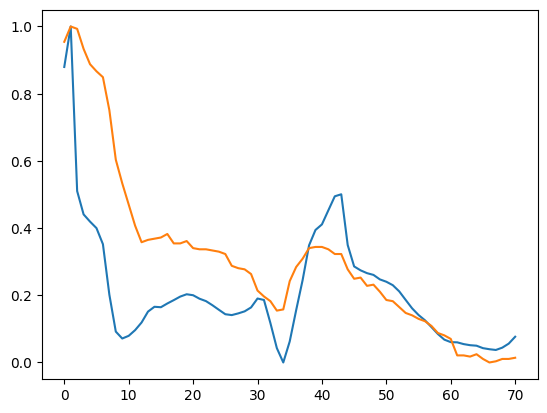

In [23]:
plt.plot((mean_grays-mean_grays.min())/(mean_grays.max()-mean_grays.min()))
plt.plot((med_grays-med_grays.min())/(med_grays.max()-med_grays.min()))


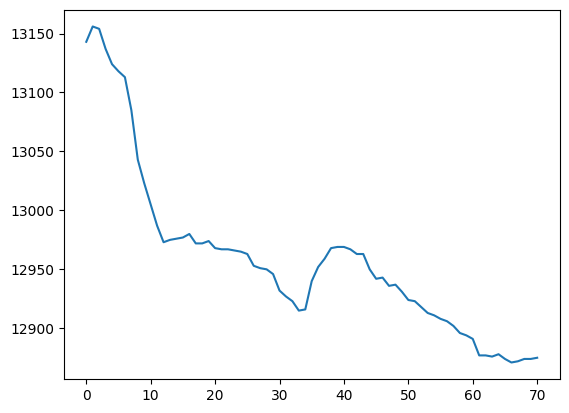

In [24]:
plt.plot(med_grays)

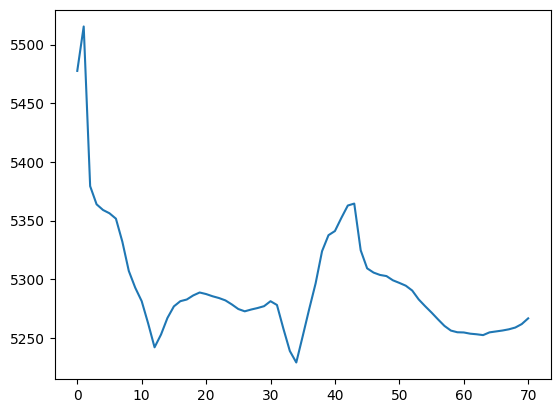

In [25]:
plt.plot(std_grays)

In [26]:
HFR_time = charge_dict[sample]['HFR']['HFRtime']
HFR = charge_dict[sample]['HFR']['fit_HFR']
HFR0 = charge_dict[sample]['HFR']['highfreqR']
t_tomo = charge_dict[sample]['t_utc_tomo'] - charge_dict[sample]['t0']
sat = charge_dict[sample]['saturation']
TH = charge_dict[sample]['TH']
crack_vol =charge_dict[sample]['crack volume']
memvol = charge_dict[sample]['membrane volume']
rel_swell = memvol/memvol.min()*100
Q = charge_dict[sample]['Q']
I = -charge_dict[sample]['I']
E = -charge_dict[sample]['E']
time = charge_dict[sample]['time']

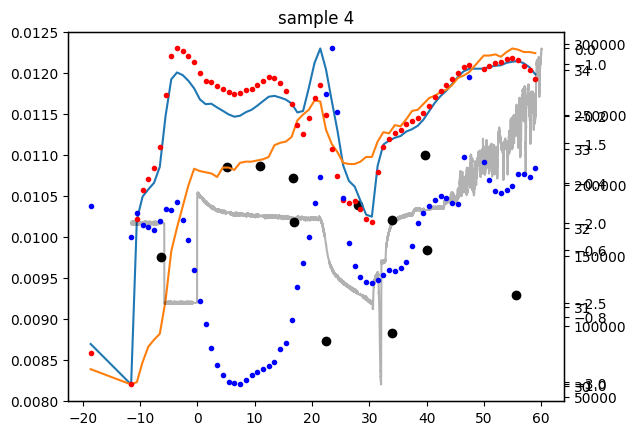

In [32]:
fig, ax = plt.subplots()
ax.plot(HFR_time/60 - 11.5, 1/HFR, 'ko')
ax.set_ylim(0.008,0.0125)
ax2 = ax.twinx()
# ax2.plot(t_tomo/60 - 11.5, -mean_grays)  #std gray also depends on membrane thickness -> pretty logical, but no physical meaning, just noise ?!
ax2.plot(t_tomo/60 - 11.5,-(mean_grays-mean_grays.min())/(mean_grays.max()-mean_grays.min()))
ax2.plot(t_tomo/60 - 11.5,-(med_grays-med_grays.min())/(med_grays.max()-med_grays.min()))
ax3 = ax.twinx()
ax3.plot(time/60 -11.5, -E, 'k', alpha = 0.3)
# ax3.set_ylim(-100,250)
ax4 = ax.twinx()
ax4.plot(t_tomo/60 - 11.5, TH, 'r.')
plt.title('sample '+sample)

ax5 = ax.twinx()
ax5.plot(t_tomo/60 - 11.5, crack_vol, 'b.')

## Grayvalue profiles

In [33]:
test2 = im[...,20]

In [37]:
prof2 = np.nanmean(test2, axis=(0,1))
prof0 = np.nanmean(test2, axis=(1,2))
prof1 = np.nanmean(test2, axis=(0,2))

In [40]:
prof = np.nanmean(im, axis = (0,2))

In [77]:
profmed = np.nanmedian(im, axis = (0,2))

In [56]:
vmin = -10
vmax = 50
cmap = cm.inferno
norm = Normalize(vmin=vmin, vmax=vmax)

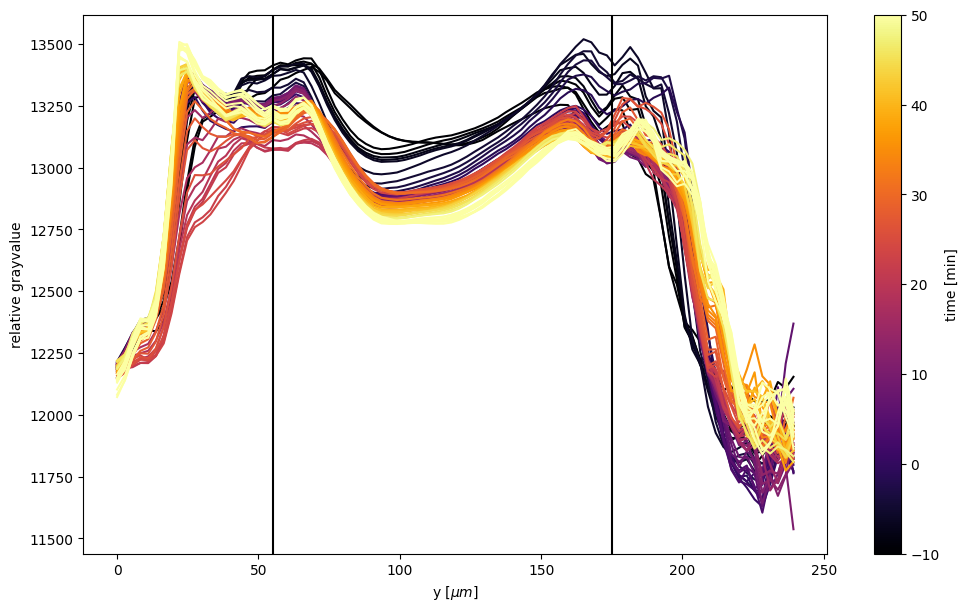

In [83]:
fig, ax = plt.subplots(figsize=(12,7))
for ts in range(prof.shape[1]):
    t = t_tomo[ts]/60-11.5
    ax.plot(np.arange(prof.shape[0])*2.75, prof[:,ts], color = cmap(norm(t)))

# ax.set_ylim(-0.03,0.02)
# ax.set_ylim(0.97,1.03)
fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=ax, label='time [min]')
ax.set_ylabel('relative grayvalue')
ax.set_xlabel('y [$\mu m$]')
y1 = 55
ax.axvline(y1,color='k')
ax.axvline(y1+120,color='k')

In [80]:
40*2.75

110.0

Text(0.5, 1.0, 'sample 4')

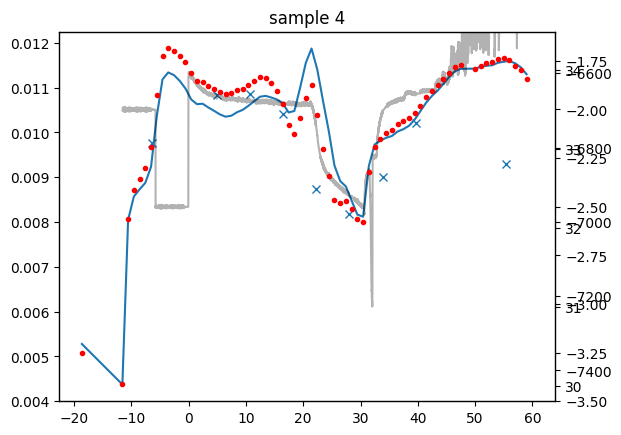

In [79]:
fig, ax = plt.subplots()
ax.plot(HFR_time/60 - 11.5, 1/HFR, 'x')
ax.set_ylim(0.004,0.01225)
ax2 = ax.twinx()
ax2.plot(t_tomo/60 - 11.5, -mean_grays)  #std gray also depends on membrane thickness -> pretty logical, but no physical meaning, just noise ?!
ax3 = ax.twinx()
ax3.plot(time/60 -11.5, -E, 'k', alpha = 0.3)
ax3.set_ylim(-3.5,-1.6)
ax4 = ax.twinx()
ax4.plot(t_tomo/60 - 11.5, TH, 'r.')
plt.title('sample '+sample)

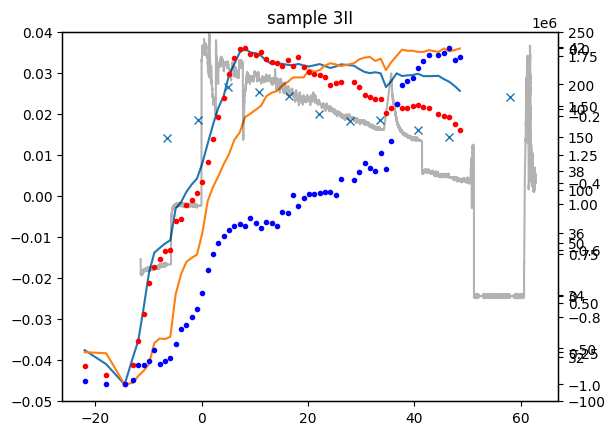

In [49]:
fig, ax = plt.subplots()
ax.plot(HFR_time/60 - 11.5, 1/HFR, 'x')
ax.set_ylim(-0.05,0.04)
ax2 = ax.twinx()
# ax2.plot(t_tomo/60 - 11.5, -mean_grays)  #std gray also depends on membrane thickness -> pretty logical, but no physical meaning, just noise ?!
ax2.plot(t_tomo/60 - 11.5,-(mean_grays-mean_grays.min())/(mean_grays.max()-mean_grays.min()))
ax2.plot(t_tomo/60 - 11.5,-(med_grays-med_grays.min())/(med_grays.max()-med_grays.min()))
ax3 = ax.twinx()
ax3.plot(time/60 -11.5, I/0.1, 'k', alpha = 0.3)
ax3.set_ylim(-100,250)
ax4 = ax.twinx()
ax4.plot(t_tomo/60 - 11.5, TH, 'r.')
plt.title('sample '+sample)

ax5 = ax.twinx()
ax5.plot(t_tomo/60 - 11.5, crack_vol, 'b.')

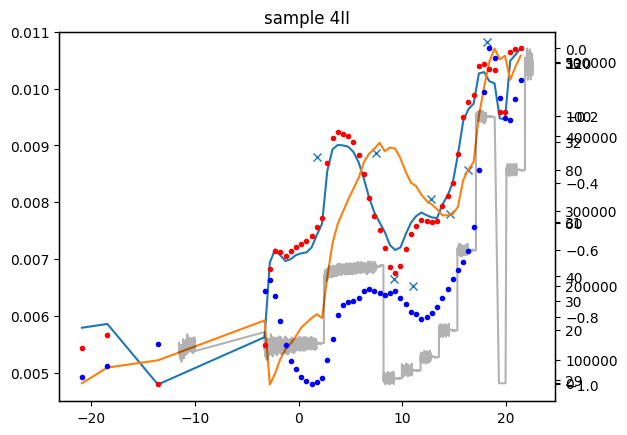

In [34]:
fig, ax = plt.subplots()
ax.plot(HFR_time/60 - 11.5, 1/HFR, 'x')
ax.set_ylim(0.0045,0.011)
ax2 = ax.twinx()
# ax2.plot(t_tomo/60 - 11.5, -mean_grays)  #std gray also depends on membrane thickness -> pretty logical, but no physical meaning, just noise ?!
ax2.plot(t_tomo/60 - 11.5,-(mean_grays-mean_grays.min())/(mean_grays.max()-mean_grays.min()))
ax2.plot(t_tomo/60 - 11.5,-(med_grays-med_grays.min())/(med_grays.max()-med_grays.min()))
ax3 = ax.twinx()
ax3.plot(time/60 -11.5, I/0.1, 'k', alpha = 0.3)
# ax3.set_ylim(-100,250)
ax4 = ax.twinx()
ax4.plot(t_tomo/60 - 11.5, TH, 'r.')
plt.title('sample '+sample)

ax5 = ax.twinx()
ax5.plot(t_tomo/60 - 11.5, crack_vol, 'b.')

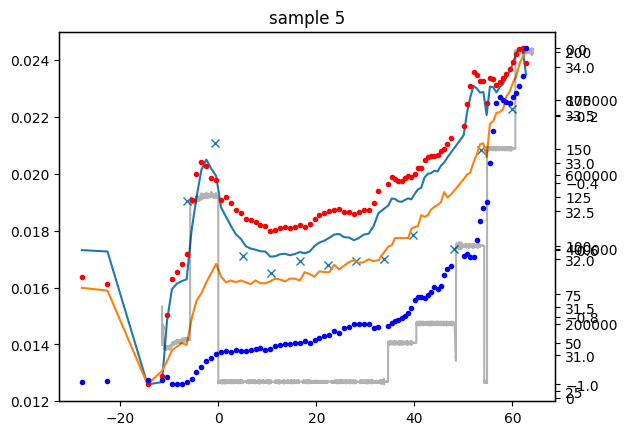

In [36]:
fig, ax = plt.subplots()
ax.plot(HFR_time/60 - 11.5, 1/HFR, 'x')
ax.set_ylim(0.012,0.025)
ax2 = ax.twinx()
# ax2.plot(t_tomo/60 - 11.5, -mean_grays)  #std gray also depends on membrane thickness -> pretty logical, but no physical meaning, just noise ?!
ax2.plot(t_tomo/60 - 11.5,-(mean_grays-mean_grays.min())/(mean_grays.max()-mean_grays.min()))
ax2.plot(t_tomo/60 - 11.5,-(med_grays-med_grays.min())/(med_grays.max()-med_grays.min()))
ax3 = ax.twinx()
ax3.plot(time/60 -11.5, I/0.1, 'k', alpha = 0.3)
# ax3.set_ylim(-100,250)
ax4 = ax.twinx()
ax4.plot(t_tomo/60 - 11.5, TH, 'r.')
plt.title('sample '+sample)

ax5 = ax.twinx()
ax5.plot(t_tomo/60 - 11.5, crack_vol, 'b.')

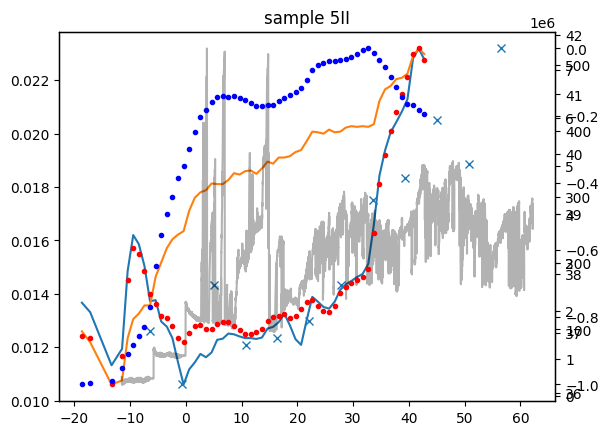

In [28]:
fig, ax = plt.subplots()
ax.plot(HFR_time/60 - 11.5, 1/HFR, 'x')
# ax.set_ylim(0.012,0.025)
ax2 = ax.twinx()
# ax2.plot(t_tomo/60 - 11.5, -mean_grays)  #std gray also depends on membrane thickness -> pretty logical, but no physical meaning, just noise ?!
ax2.plot(t_tomo/60 - 11.5,-(mean_grays-mean_grays.min())/(mean_grays.max()-mean_grays.min()))
ax2.plot(t_tomo/60 - 11.5,-(med_grays-med_grays.min())/(med_grays.max()-med_grays.min()))
ax3 = ax.twinx()
ax3.plot(time/60 -11.5, I/0.1, 'k', alpha = 0.3)
# ax3.set_ylim(-100,250)
ax4 = ax.twinx()
ax4.plot(t_tomo/60 - 11.5, TH, 'r.')
plt.title('sample '+sample)

ax5 = ax.twinx()
ax5.plot(t_tomo/60 - 11.5, crack_vol, 'b.')

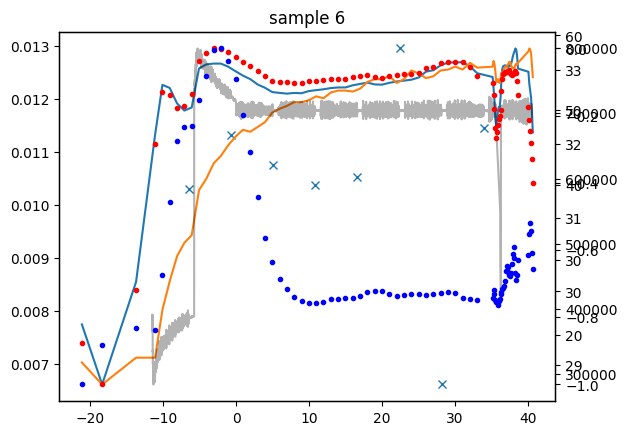

In [27]:
fig, ax = plt.subplots()
ax.plot(HFR_time/60 - 11.5, 1/HFR, 'x')
# ax.set_ylim(0.012,0.025)
ax2 = ax.twinx()
# ax2.plot(t_tomo/60 - 11.5, -mean_grays)  #std gray also depends on membrane thickness -> pretty logical, but no physical meaning, just noise ?!
ax2.plot(t_tomo/60 - 11.5,-(mean_grays-mean_grays.min())/(mean_grays.max()-mean_grays.min()))
ax2.plot(t_tomo/60 - 11.5,-(med_grays-med_grays.min())/(med_grays.max()-med_grays.min()))
ax3 = ax.twinx()
ax3.plot(time/60 -11.5, I/0.1, 'k', alpha = 0.3)
# ax3.set_ylim(-100,250)
ax4 = ax.twinx()
ax4.plot(t_tomo/60 - 11.5, TH, 'r.')
plt.title('sample '+sample)

ax5 = ax.twinx()
ax5.plot(t_tomo/60 - 11.5, crack_vol, 'b.')

In [22]:
import ctypes
def trim_memory() -> int:
    libc = ctypes.CDLL("libc.so.6")
    return libc.malloc_trim(0)

In [32]:
trim_memory()

1